In [241]:
import numpy as np
import csv
import pandas as pd
from scipy.signal import find_peaks
#import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib import cm
import matplotlib.patches as mpatches
import scipy as sp
import os
from pathlib import Path

from shapely.geometry.polygon import Polygon
from shapely.geometry import Point
from shapely.plotting import plot_polygon, plot_points
from descartes.patch import PolygonPatch

In [2]:
SAVEDIR = Path(os.path.expanduser("~/ECM_mod_output/UMAP_stoch_figs/"))
if not os.path.exists(SAVEDIR):
    os.mkdir(SAVEDIR)

In [3]:
#UMAP stochastic
embedding_prot_erl_7_7_1_1 = pd.read_csv(str(SAVEDIR) + '/embedding_erl_4-9_1_1.csv',header=None)
embedding_prot_erl_7_7_2_1 = pd.read_csv(str(SAVEDIR) + '/embedding_erl_4-9_2_1.csv',header=None)
embedding_prot_erl_7_7_3_1 = pd.read_csv(str(SAVEDIR) + '/embedding_erl_4-9_3_1.csv',header=None)

#prot stochastic
all_prot_erl_7_7_1_1 = pd.read_csv(str(SAVEDIR) + '/all_prot_erl_4-9_1_1.csv',header=None)
all_prot_erl_7_7_2_1 = pd.read_csv(str(SAVEDIR) + '/all_prot_erl_4-9_2_1.csv',header=None)
all_prot_erl_7_7_3_1 = pd.read_csv(str(SAVEDIR) + '/all_prot_erl_4-9_3_1.csv',header=None)

In [4]:
#UMAP stochastic
embedding_prot_dmso_7_7_1_1 = pd.read_csv(str(SAVEDIR) + '/embedding_dmso_4-9_1_1.csv',header=None)
embedding_prot_dmso_7_7_2_1 = pd.read_csv(str(SAVEDIR) + '/embedding_dmso_4-9_2_1.csv',header=None)
embedding_prot_dmso_7_7_3_1 = pd.read_csv(str(SAVEDIR) + '/embedding_dmso_4-9_3_1.csv',header=None)

#prot stochastic
all_prot_dmso_7_7_1_1 = pd.read_csv(str(SAVEDIR) + '/all_prot_dmso_4-9_1_1.csv',header=None)
all_prot_dmso_7_7_2_1 = pd.read_csv(str(SAVEDIR) + '/all_prot_dmso_4-9_2_1.csv',header=None)
all_prot_dmso_7_7_3_1 = pd.read_csv(str(SAVEDIR) + '/all_prot_dmso_4-9_3_1.csv',header=None)

In [5]:
#times

all_time_stoch = pd.read_csv(str(SAVEDIR) + '/all_time_erl_4-9_1_1.csv',header=None)
all_time_at_stoch = pd.read_csv(str(SAVEDIR) + '/all_time_at_erl_4-9_1_1.csv',header=None)

In [6]:
embedding_tmp = np.loadtxt(str(SAVEDIR) + '/embedding_all_ode.csv', delimiter=',')
embedding_index = np.loadtxt(str(SAVEDIR) + '/embedding_all_ode_index.csv', delimiter=',')

In [7]:
window_size = len(all_prot_erl_7_7_3_1.columns)/18
cyce=int((window_size*11+window_size/2)-1)
cdc20=int((window_size*17+window_size/2)-1)

In [8]:
def restructProt(protDF, embedDF, timeDF):
    peaks_E, _ = find_peaks(protDF[cyce], prominence = 40/200, distance = 10)
    peaks_cdc, _ = find_peaks(protDF[cdc20], prominence = 40/200, distance = 10)
    
    mit_win = pd.DataFrame()
    time_win = pd.DataFrame()
    umap_win = pd.DataFrame()
    
    for n in range(2,len(peaks_cdc)-3):   #make sure we have divisions at ends 
        tmp_mit = peaks_cdc[n]
        tmp_mit2 = peaks_cdc[n+1]
        tmp_mit3 = peaks_cdc[n+2]
        tmp_mit4 = peaks_cdc[n+3]
        
        tmp_g1_s = peaks_E[(tmp_mit < peaks_E) & (peaks_E < tmp_mit2)]
        tmp_g1_s_2 = peaks_E[(tmp_mit2 < peaks_E) & (peaks_E < tmp_mit3)]
        tmp_g1_s_3 = peaks_E[(tmp_mit3 < peaks_E) & (peaks_E < tmp_mit4)]    
             
        if (np.size(tmp_g1_s) > 0) & (np.size(tmp_g1_s_2)>0) & (np.size(tmp_g1_s_3)>0):
            ordered = [tmp_mit, tmp_g1_s[0], tmp_mit2, tmp_g1_s_2[0], tmp_mit3, tmp_g1_s_3[0], tmp_mit4]
            g1_len_tmp = np.array(timeDF.iloc[ordered[3],0]) - np.array(timeDF.iloc[[ordered[2]],0])
            tmp_prot = protDF.iloc[int(ordered[1]):int(ordered[3]),:]
            tmp_umap = embedDF.iloc[int(ordered[1]):int(ordered[3]),:]
            tmp_time = timeDF.iloc[int(ordered[1]):int(ordered[3]),:]
            tmp = [g1_len_tmp]*len(tmp_time)
            tmp = np.concatenate(tmp, axis=0)
            tmp_time.insert(1, 'G1', tmp)
            
            mit_win = pd.concat([mit_win,tmp_prot],ignore_index=True)
            time_win = pd.concat([time_win, tmp_time], ignore_index=True)
            umap_win = pd.concat([umap_win, tmp_umap], ignore_index=True)
            
    return mit_win, time_win, umap_win

In [9]:
def splitIMT(protDF, embedDF, timeDF):
    peaks_E, _ = find_peaks(protDF[cyce], prominence = 40/200, distance = 10)
    peaks_cdc, _ = find_peaks(protDF[cdc20], prominence = 40/200, distance = 10)
    
    mit_win = []
    time_win = pd.DataFrame()
    umap_win = []
    count = 0
    for n in range(2,len(peaks_cdc)-3):   #make sure we have divisions at ends 
        tmp_mit = peaks_cdc[n]
        tmp_mit2 = peaks_cdc[n+1]
        tmp_mit3 = peaks_cdc[n+2]
        tmp_mit4 = peaks_cdc[n+3]
        
        tmp_g1_s = peaks_E[(tmp_mit < peaks_E) & (peaks_E < tmp_mit2)]
        tmp_g1_s_2 = peaks_E[(tmp_mit2 < peaks_E) & (peaks_E < tmp_mit3)]
        tmp_g1_s_3 = peaks_E[(tmp_mit3 < peaks_E) & (peaks_E < tmp_mit4)]    
             
        if (np.size(tmp_g1_s) > 0) & (np.size(tmp_g1_s_2)>0) & (np.size(tmp_g1_s_3)>0):
            ordered = [tmp_mit, tmp_g1_s[0], tmp_mit2, tmp_g1_s_2[0], tmp_mit3, tmp_g1_s_3[0], tmp_mit4]
            g1_len_tmp = np.array(timeDF.iloc[ordered[3],0]) - np.array(timeDF.iloc[[ordered[2]],0])
            tmp_prot = protDF.iloc[int(ordered[2]):int(ordered[4]),:]
            tmp_arr = tmp_prot.to_numpy()
            tmp_umap = embedDF.iloc[int(ordered[2]):int(ordered[4]),:]
            tmp_umap_arr = tmp_umap.to_numpy()
            tmp_time = timeDF.iloc[int(ordered[2]):int(ordered[4]),:]
            tmp = [g1_len_tmp]*len(tmp_time)
            tmp = np.concatenate(tmp, axis=0)
            tmp_time.insert(1, 'G1', tmp)
            
            mit_win = [mit_win, tmp_arr]
            time_win = pd.concat([time_win, tmp_time], ignore_index=True)
            if len(umap_win)==0:
                umap_win = [tmp_umap_arr]
            else:
                umap_win.append(tmp_umap_arr)
            count += 1
    return tmp_arr, time_win, umap_win, count

In [10]:
mit_win_erl_1_1, time_win_erl_1_1, umap_win_erl_1_1 = restructProt(all_prot_erl_7_7_1_1, embedding_prot_erl_7_7_1_1, all_time_at_stoch)
mit_win_erl_2_1, time_win_erl_2_1, umap_win_erl_2_1 = restructProt(all_prot_erl_7_7_2_1, embedding_prot_erl_7_7_2_1, all_time_at_stoch)
mit_win_erl_3_1, time_win_erl_3_1, umap_win_erl_3_1 = restructProt(all_prot_erl_7_7_3_1, embedding_prot_erl_7_7_3_1, all_time_at_stoch)

In [11]:
mit_all_erl_1_1, test1, umap_all_erl_1_1, count = splitIMT(all_prot_erl_7_7_1_1, embedding_prot_erl_7_7_1_1, all_time_at_stoch)
mit_all_erl_2_1, test2, umap_all_erl_2_1, count = splitIMT(all_prot_erl_7_7_2_1, embedding_prot_erl_7_7_2_1, all_time_at_stoch)
mit_all_erl_3_1, test3, umap_all_erl_3_1, count = splitIMT(all_prot_erl_7_7_3_1, embedding_prot_erl_7_7_3_1, all_time_at_stoch)

In [12]:
mit_win_dmso_1_1, time_win_dmso_1_1, umap_win_dmso_1_1 = restructProt(all_prot_dmso_7_7_1_1, embedding_prot_dmso_7_7_1_1, all_time_at_stoch)
mit_win_dmso_2_1, time_win_dmso_2_1, umap_win_dmso_2_1 = restructProt(all_prot_dmso_7_7_2_1, embedding_prot_dmso_7_7_2_1, all_time_at_stoch)
mit_win_dmso_3_1, time_win_dmso_3_1, umap_win_dmso_3_1 = restructProt(all_prot_dmso_7_7_3_1, embedding_prot_dmso_7_7_3_1, all_time_at_stoch)

# Original (Informal) Analysis

In [304]:
def plot_by_class(UMAP_vals):
    fig = plt.figure()
    erl_slow = 0
    erl_fast = 0
    dmso = 0

    
    xmin, xmax = -5, 15
    ymin, ymax = -5, 15
    ind = np.where(embedding_index == 1) 
    x=np.ndarray.tolist(embedding_tmp[ind,0])
    y=np.ndarray.tolist(embedding_tmp[ind,1])

    for ii in range(1001,2001):
        ind = np.where(embedding_index == ii) 
        x=np.ndarray.tolist(embedding_tmp[ind,0])
        y=np.ndarray.tolist(embedding_tmp[ind,1])
        plt.plot(x[0][int(len(x[0])/2):], y[0][int(len(x[0])/2):], color='lightblue')
    ind = np.where(embedding_index == 1001) 
    x=np.ndarray.tolist(embedding_tmp[ind,0])
    y=np.ndarray.tolist(embedding_tmp[ind,1])    
    dmso_plot = mpatches.Patch(color='lightblue')
    

    for ii in range(0,113):
        ind = np.where(embedding_index == ii) 
        x=np.ndarray.tolist(embedding_tmp[ind,0])
        y=np.ndarray.tolist(embedding_tmp[ind,1])
        plt.plot(x[0][int(len(x[0])/2):], y[0][int(len(x[0])/2):], color='lightgreen')
    ind = np.where(embedding_index == 1) 
    x=np.ndarray.tolist(embedding_tmp[ind,0])
    y=np.ndarray.tolist(embedding_tmp[ind,1])
    erl_slow_plot = mpatches.Patch(color='lightgreen')
    
    for ii in range(114,1001):
        ind = np.where(embedding_index == ii) 
        x=np.ndarray.tolist(embedding_tmp[ind,0])
        y=np.ndarray.tolist(embedding_tmp[ind,1])
        plt.plot(x[0][int(len(x[0])/2):], y[0][int(len(x[0])/2):], color='lightgrey')
    ind = np.where(embedding_index == 113) 
    x=np.ndarray.tolist(embedding_tmp[ind,0])
    y=np.ndarray.tolist(embedding_tmp[ind,1])
    erl_fast_plot = mpatches.Patch(color='lightgrey')

    for num in range(len(UMAP_vals)):
        state = [0] * len(UMAP_vals[num])
        for val in range(len(UMAP_vals[num])): 
            if (UMAP_vals[num][val,0]>10) & (UMAP_vals[num][val,1]>10):
                state[val]=2
            elif (7>UMAP_vals[num][val,0]>4) & (7>UMAP_vals[num][val,1]>4):
                state[val]=1

        if any(item==2 for item in state):
            color='darkgreen'
            erl_slow += 1
        elif any(item==1 for item in state):
            color='darkblue'
            dmso += 1
        else:
            color='dimgrey'
            erl_fast += 1

        plt.plot(UMAP_vals[num][:,0], UMAP_vals[num][:,1], c=color, lw=0.3)
        classes = [erl_slow, erl_fast, dmso]
        total = erl_slow + erl_fast + dmso
        perc = [(x/total)*100 for x in classes]
        
        plt.xlim([xmin, xmax])
        plt.ylim([ymin, ymax])
        plt.xticks([-5, 0, 5, 10])
        plt.yticks([-5, 0, 5, 10])
    
        plt.legend([dmso_plot, erl_fast_plot, erl_slow_plot], 
                   (f'+DMSO: {round(perc[2],2)}%', f'+ERL fast: {round(perc[1],2)}%', f'+ERL slow: {round(perc[0],2)}%'), 
                   loc=2, fontsize=8)
        
        '+DMSO, ODE' '+ERL, ODE'
    return classes

[48, 24, 2]

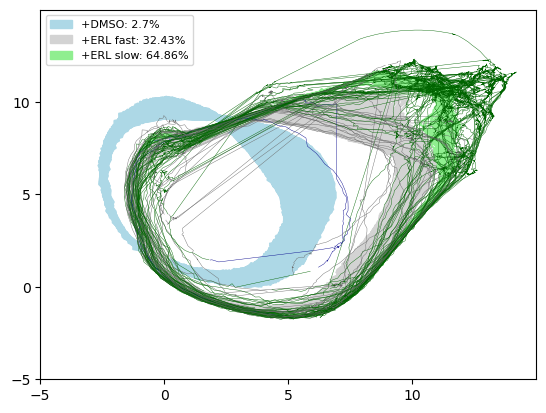

In [305]:
plot_by_class(umap_all_erl_1_1)

[16, 93, 33]

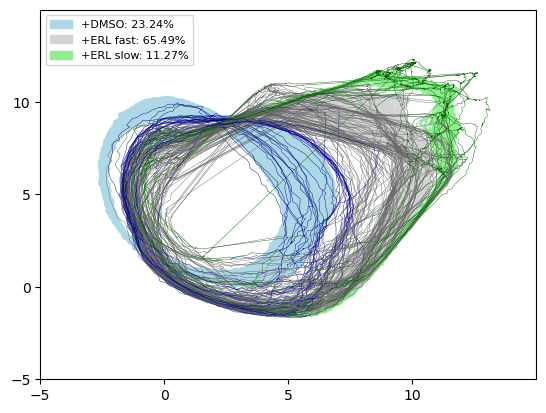

In [188]:
plot_by_class(umap_all_erl_2_1)

[4, 94, 40]

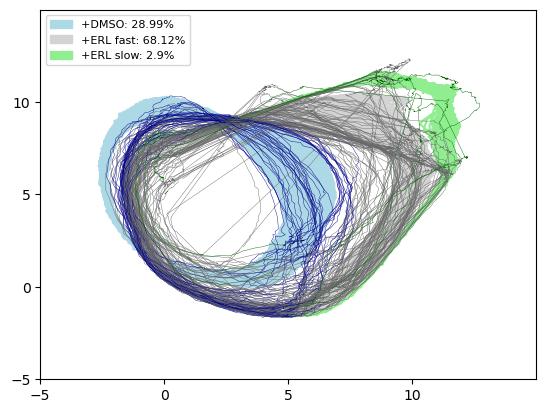

In [189]:
plot_by_class(umap_all_erl_3_1)

# New (Polygon Method) Analysis

True
False


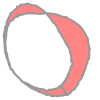

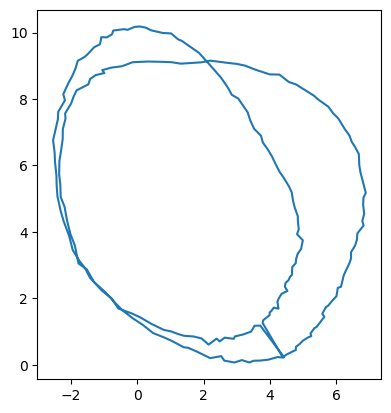

In [258]:
ind = np.where(embedding_index == 1001)
x = np.ndarray.tolist(embedding_tmp[ind,0])
y = np.ndarray.tolist(embedding_tmp[ind,1])  
boundary1 = list(zip(x[0][int(len(x[0])/2):],y[0][int(len(x[0])/2):]))

ind = np.where(embedding_index == 2000)
x = np.ndarray.tolist(embedding_tmp[ind,0])
y = np.ndarray.tolist(embedding_tmp[ind,1])
boundary2 = list(zip(x[0][int(len(x[0])/2):],y[0][int(len(x[0])/2):]))

full_boundary = boundary1 + boundary2
full_boundary = tuple(map(tuple,full_boundary)) # Transform into tuple

poly1 = Polygon(full_boundary)    # Create filling Polygon
plt.plot(*poly1.exterior.xy)

point=Point(5,5)
print(poly1.contains(point))
point=Point(6,2)
print(poly1.contains(point))

poly1

True
False


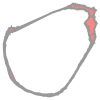

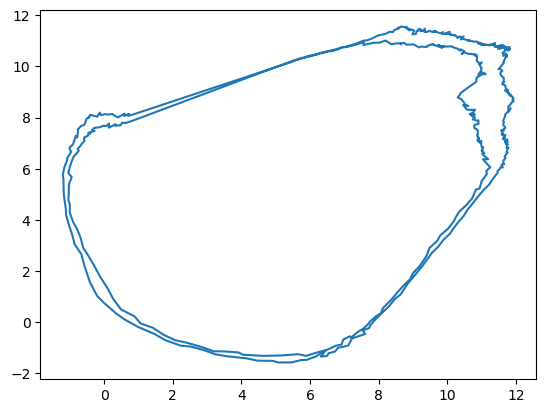

In [259]:
ind = np.where(embedding_index == 1)
x = np.ndarray.tolist(embedding_tmp[ind,0])
y = np.ndarray.tolist(embedding_tmp[ind,1])  
boundary1 = list(zip(x[0][int(len(x[0])/2):],y[0][int(len(x[0])/2):]))

ind = np.where(embedding_index == 112)
x = np.ndarray.tolist(embedding_tmp[ind,0])
y = np.ndarray.tolist(embedding_tmp[ind,1])
boundary2 = list(zip(x[0][int(len(x[0])/2):],y[0][int(len(x[0])/2):]))

full_boundary = boundary1 + boundary2
full_boundary = tuple(map(tuple,full_boundary)) # Transform into tuple

poly2 = Polygon(full_boundary)    # Create filling Polygon
plt.plot(*poly2.exterior.xy)

point=Point(11,9)
print(poly2.contains(point))
point=Point(6,2)
print(poly2.contains(point))

poly2

True
False


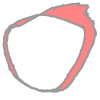

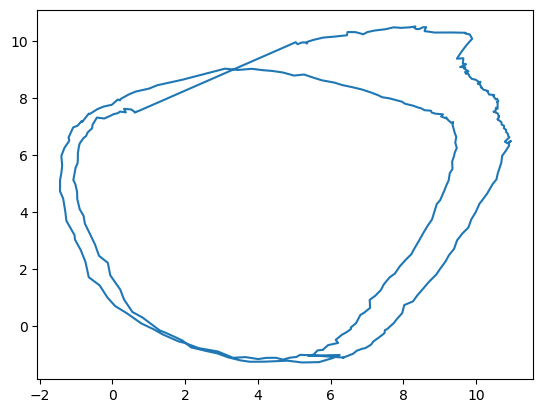

In [260]:
ind = np.where(embedding_index == 114)
x = np.ndarray.tolist(embedding_tmp[ind,0])
y = np.ndarray.tolist(embedding_tmp[ind,1])  
boundary1 = list(zip(x[0][int(len(x[0])/2):],y[0][int(len(x[0])/2):]))

ind = np.where(embedding_index == 1000)
x = np.ndarray.tolist(embedding_tmp[ind,0])
y = np.ndarray.tolist(embedding_tmp[ind,1])
boundary2 = list(zip(x[0][int(len(x[0])/2):],y[0][int(len(x[0])/2):]))

full_boundary = boundary1 + boundary2
full_boundary = tuple(map(tuple,full_boundary)) # Transform into tuple

poly3 = Polygon(full_boundary)    # Create filling Polygon
plt.plot(*poly3.exterior.xy)

point=Point(9,4)
print(poly3.contains(point))
point=Point(6,2)
print(poly3.contains(point))

poly3

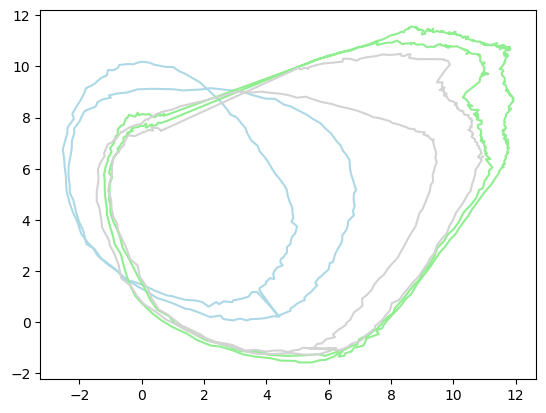

In [361]:
fig = plt.figure()
plt.plot(*poly1.exterior.xy, color = 'lightblue')
plt.plot(*poly2.exterior.xy, color = 'lightgreen')
plt.plot(*poly3.exterior.xy, color = 'lightgrey')

In [468]:
def plot_by_class(UMAP_vals):
    fig = plt.figure()
    erl_slow = 0
    erl_fast = 0
    dmso = 0
    
    perc_not_counted = []
    
    xmin, xmax = -5, 15
    ymin, ymax = -5, 15
    ind = np.where(embedding_index == 1) 
    x=np.ndarray.tolist(embedding_tmp[ind,0])
    y=np.ndarray.tolist(embedding_tmp[ind,1])

    
    
    # DMSO Region
    ind = np.where(embedding_index == 1001)
    x = np.ndarray.tolist(embedding_tmp[ind,0])
    y = np.ndarray.tolist(embedding_tmp[ind,1])  
    boundary1 = list(zip(x[0][int(len(x[0])/2):],y[0][int(len(x[0])/2):]))

    ind = np.where(embedding_index == 2000)
    x = np.ndarray.tolist(embedding_tmp[ind,0])
    y = np.ndarray.tolist(embedding_tmp[ind,1])
    boundary2 = list(zip(x[0][int(len(x[0])/2):],y[0][int(len(x[0])/2):]))

    full_boundary = boundary1 + boundary2
    full_boundary = tuple(map(tuple,full_boundary)) # Transform into tuple

    poly1 = Polygon(full_boundary)    # Create filling Polygon
    plt.plot(*poly1.exterior.xy, color = 'lightblue')

    dmso_plot = mpatches.Patch(color='lightblue')
    
    

    
    # ERL Slow Region
    ind = np.where(embedding_index == 1)
    x = np.ndarray.tolist(embedding_tmp[ind,0])
    y = np.ndarray.tolist(embedding_tmp[ind,1])  
    boundary1 = list(zip(x[0][int(len(x[0])/2):],y[0][int(len(x[0])/2):]))

    ind = np.where(embedding_index == 112)
    x = np.ndarray.tolist(embedding_tmp[ind,0])
    y = np.ndarray.tolist(embedding_tmp[ind,1])
    boundary2 = list(zip(x[0][int(len(x[0])/2):],y[0][int(len(x[0])/2):]))

    full_boundary = boundary1 + boundary2
    full_boundary = tuple(map(tuple,full_boundary)) # Transform into tuple

    poly2 = Polygon(full_boundary)    # Create filling Polygon
    plt.plot(*poly2.exterior.xy, color = 'lightgreen')

    erl_slow_plot = mpatches.Patch(color='lightgreen')
    



    # ERL Fast Region
    
    ind = np.where(embedding_index == 114)
    x = np.ndarray.tolist(embedding_tmp[ind,0])
    y = np.ndarray.tolist(embedding_tmp[ind,1])  
    boundary1 = list(zip(x[0][int(len(x[0])/2):],y[0][int(len(x[0])/2):]))

    ind = np.where(embedding_index == 1000)
    x = np.ndarray.tolist(embedding_tmp[ind,0])
    y = np.ndarray.tolist(embedding_tmp[ind,1])
    boundary2 = list(zip(x[0][int(len(x[0])/2):],y[0][int(len(x[0])/2):]))

    full_boundary = boundary1 + boundary2
    full_boundary = tuple(map(tuple,full_boundary)) # Transform into tuple

    poly3 = Polygon(full_boundary)    # Create filling Polygon
    plt.plot(*poly3.exterior.xy, color = 'lightgrey')

    erl_fast_plot = mpatches.Patch(color='lightgrey')
    



    for num in range(len(UMAP_vals)):
        
        erl_slow_count = 0
        erl_fast_count = 0
        dmso_count = 0
        num_pts_outside = 0
        
        for val in range(len(UMAP_vals[num])): 
            point = Point(UMAP_vals[num][val])
            if (poly1.contains(point) & poly2.contains(point) & poly3.contains(point)):
                dmso_count += 1
                erl_slow_count += 1
                erl_fast_count += 1
            elif (poly2.contains(point) & poly3.contains(point)):
                erl_slow_count += 1
                erl_fast_count += 1
            elif (poly1.contains(point) & poly2.contains(point)):
                dmso_count += 1
                erl_slow_count += 1
            elif (poly1.contains(point) & poly3.contains(point)):
                dmso_count += 1
                erl_fast_count += 1
            elif (poly1.contains(point)):
                dmso_count += 1
            elif (poly2.contains(point)):
                erl_slow_count += 1
            else:
                num_pts_outside += 1
            
            
        traj_class = [erl_slow_count, erl_fast_count, dmso_count] 
        point_total = erl_slow_count + erl_fast_count + dmso_count + num_pts_outside
        traj_perc = [(x/point_total)*100 for x in traj_class]
        
        
        if (num == 0):
            perc_not_counted = [round((num_pts_outside/point_total)*100,2)]
        else:
            perc_not_counted.append(round((num_pts_outside/point_total)*100,2))
        
            
        if ((round(traj_perc[0],2) > round(traj_perc[1],2)) & (round(traj_perc[0],2) > round(traj_perc[2],2))):
            color='darkgreen'
            erl_slow += 1
        elif ((round(traj_perc[2],2) > round(traj_perc[0],2)) & (round(traj_perc[2],2) > round(traj_perc[1],2))):
            color='darkblue'
            dmso += 1
        else:
            color='dimgrey'
            erl_fast += 1
                
            
        plt.plot(UMAP_vals[num][:,0], UMAP_vals[num][:,1], c=color, lw=0.3)
        classes = [erl_slow, erl_fast, dmso]
        total = erl_slow + erl_fast + dmso
        perc = [(x/total)*100 for x in classes]
        
        plt.xlim([xmin, xmax])
        plt.ylim([ymin, ymax])
        plt.xticks([-5, 0, 5, 10])
        plt.yticks([-5, 0, 5, 10])
    
        plt.legend([dmso_plot, erl_fast_plot, erl_slow_plot], 
                    (f'+DMSO: {round(perc[2],2)}%', f'+ERL fast: {round(perc[1],2)}%', f'+ERL slow: {round(perc[0],2)}%'), 
                    loc=2, fontsize=8)
        
        '+DMSO, ODE' '+ERL, ODE'
            
    return classes, perc_not_counted

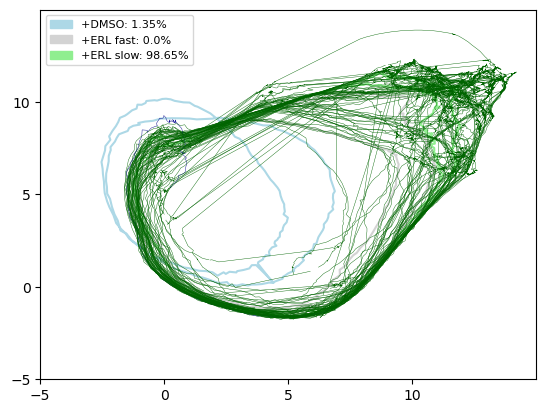

In [479]:
result = plot_by_class(umap_all_erl_1_1)

Text(0, 0.5, 'Number of Trajectories')

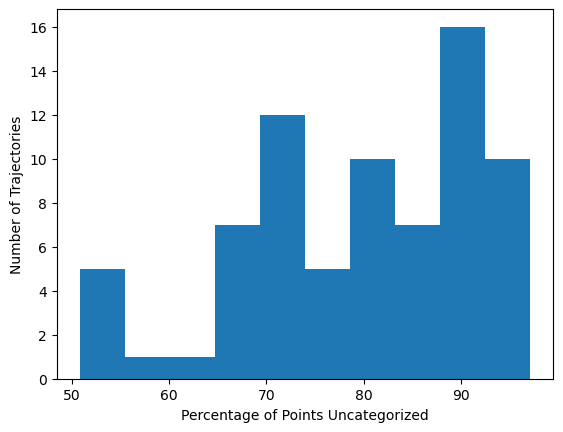

In [480]:
plt.hist(result[1])
plt.xlabel('Percentage of Points Uncategorized')
plt.ylabel('Number of Trajectories')

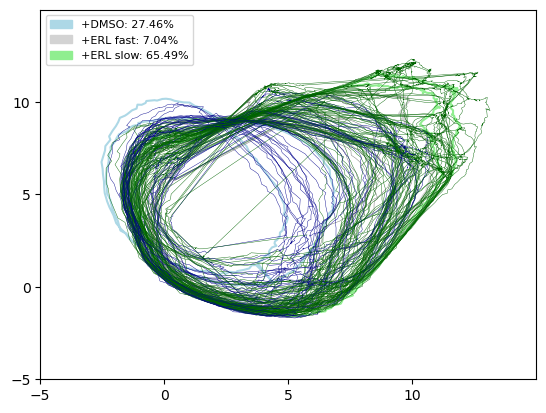

In [481]:
result = plot_by_class(umap_all_erl_2_1)

Text(0, 0.5, 'Number of Trajectories')

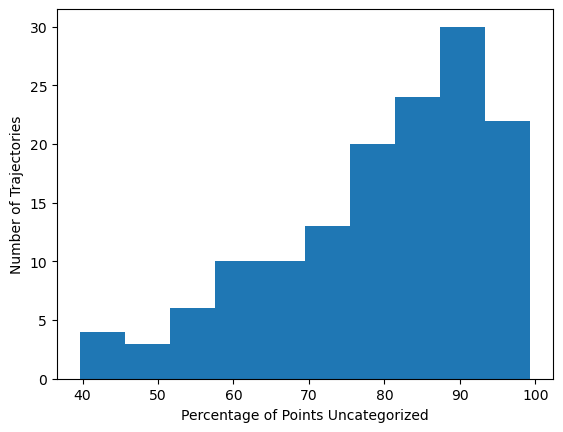

In [482]:
plt.hist(result[1])
plt.xlabel('Percentage of Points Uncategorized')
plt.ylabel('Number of Trajectories')

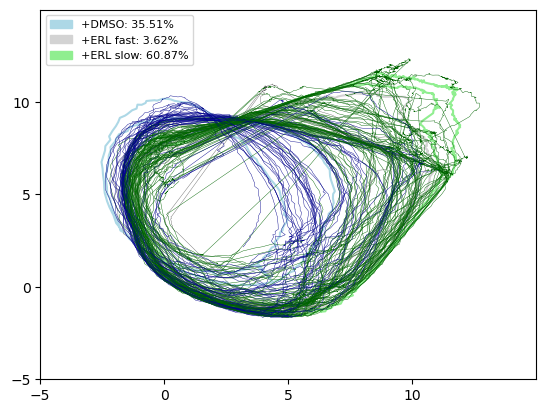

In [483]:
result = plot_by_class(umap_all_erl_3_1)

Text(0, 0.5, 'Number of Trajectories')

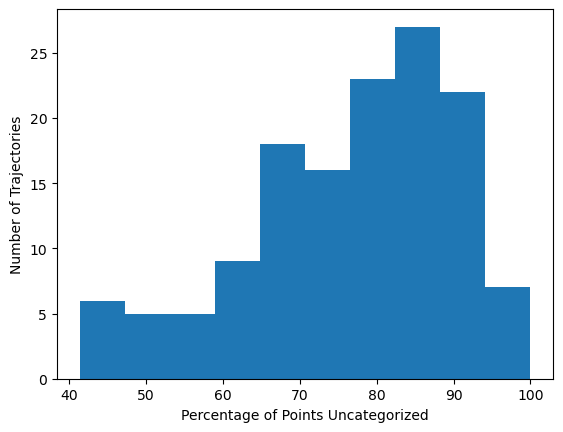

In [484]:
plt.hist(result[1])
plt.xlabel('Percentage of Points Uncategorized')
plt.ylabel('Number of Trajectories')